In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
titanic = sns.load_dataset("titanic")

In [3]:
titanic.head
titanic.info()
titanic.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [4]:
features = ["pclass","sex","fare","embarked","age"]
target = ["survived"]

In [5]:
# fiil up missing value

from sklearn.impute import SimpleImputer

imp_median = SimpleImputer(strategy="median")
titanic[["age"]] = imp_median.fit_transform(titanic[["age"]])

imp_freq = SimpleImputer(strategy="most_frequent")
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

In [6]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [7]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [8]:
titanic.shape

(891, 15)

In [9]:
# encode
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

titanic["sex"] = le.fit_transform(titanic["sex"])

titanic["embarked"] = le.fit_transform(titanic["embarked"])

In [10]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,2,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,0,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,2,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,2,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,2,Third,man,True,NaN,Southampton,no,True


In [11]:
X = titanic[features]
y = titanic["survived"]

In [12]:
X

,pclass,sex,fare,embarked,age
0,3,1,7.2500,2,22.0
1,1,0,71.2833,0,38.0
2,3,0,7.9250,2,26.0
3,1,0,53.1000,2,35.0
4,3,1,8.0500,2,35.0
...,...,...,...,...,...
886,2,1,13.0000,2,27.0
887,1,0,30.0000,2,19.0
888,3,0,23.4500,2,28.0
889,1,1,30.0000,0,26.0


In [13]:
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: survived, Length: 891, dtype: int64

In [14]:
X_train,X_test, y_train, y_test = train_test_split(
    X,y,test_size = 0.3, random_state = 42)

In [15]:
X_train.head()

,pclass,sex,fare,embarked,age
445,1,1,81.8583,2,4.0
650,3,1,7.8958,2,28.0
172,3,0,11.1333,2,1.0
450,2,1,27.7500,2,36.0
314,2,1,26.2500,2,43.0


In [16]:
# DT model
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()
model.fit(X_train,y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [17]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)
print("Accuracy: ",accuracy_score(y_test,y_pred))

Accuracy:  0.753731343283582


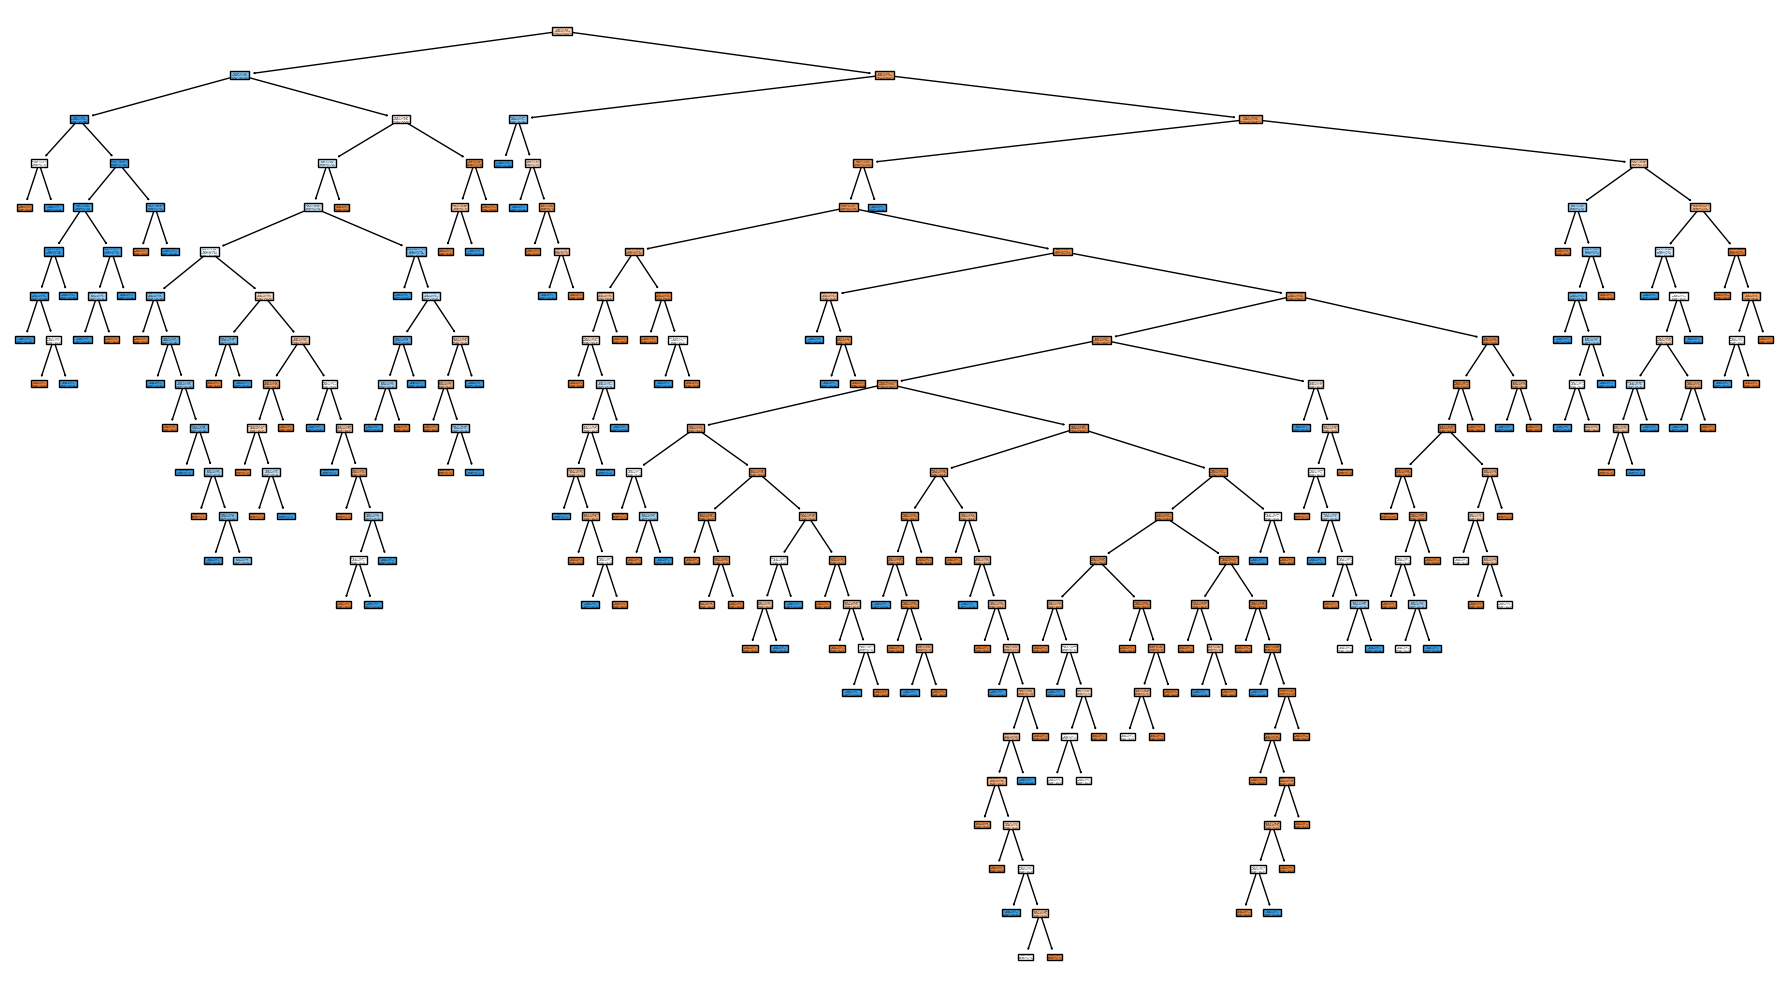

In [18]:
from sklearn.tree import plot_tree

plt.figure(figsize = (18,10))
plot_tree(
    model,
    feature_names = X.columns,
    class_names = ["Died","Survived"],
    filled = True
)

plt.tight_layout()
plt.show()
    

# Decision tree with pre pruning


for depth=2 , accuracy = 0.7723880597014925 
for depth=3 , accuracy = 0.8059701492537313 
for depth=4 , accuracy = 0.8246268656716418 


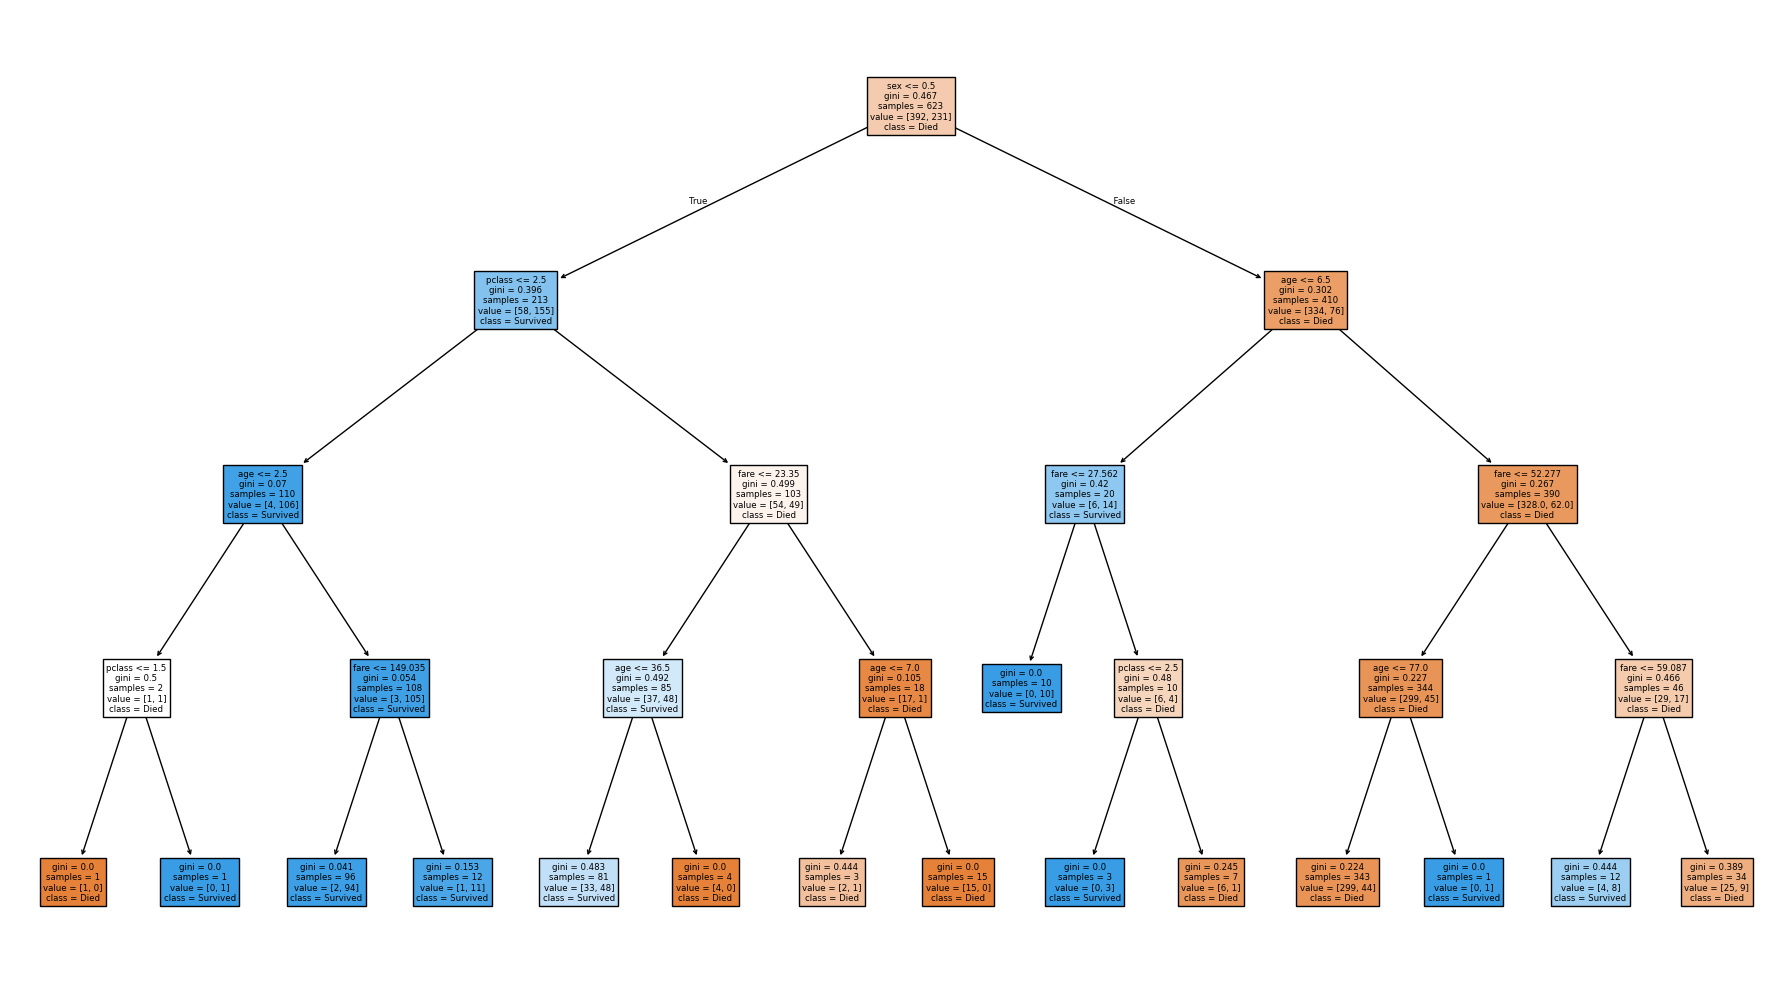

for depth=5 , accuracy = 0.7985074626865671 
for depth=6 , accuracy = 0.7835820895522388 
for depth=7 , accuracy = 0.7835820895522388 
for depth=8 , accuracy = 0.7985074626865671 
for depth=9 , accuracy = 0.7686567164179104 
for depth=10 , accuracy = 0.7761194029850746 


In [19]:
max_depths = [2,3,4,5,6,7,8,9,10]
for depth in max_depths:
    model = DecisionTreeClassifier(max_depth = depth)
    model.fit(X_train,y_train)

    acc = model.score(X_test,y_test)
    print(f"for depth={depth} , accuracy = {acc} ")

    if depth== 4:
        plt.figure(figsize = (18,10))
        plot_tree(
            model,
            feature_names = X.columns,
            class_names = ["Died","Survived"],
            filled = True
        )

        plt.tight_layout()
        plt.show()

for sample split=5 , accuracy = 0.8246268656716418 
for sample split=10 , accuracy = 0.8246268656716418 


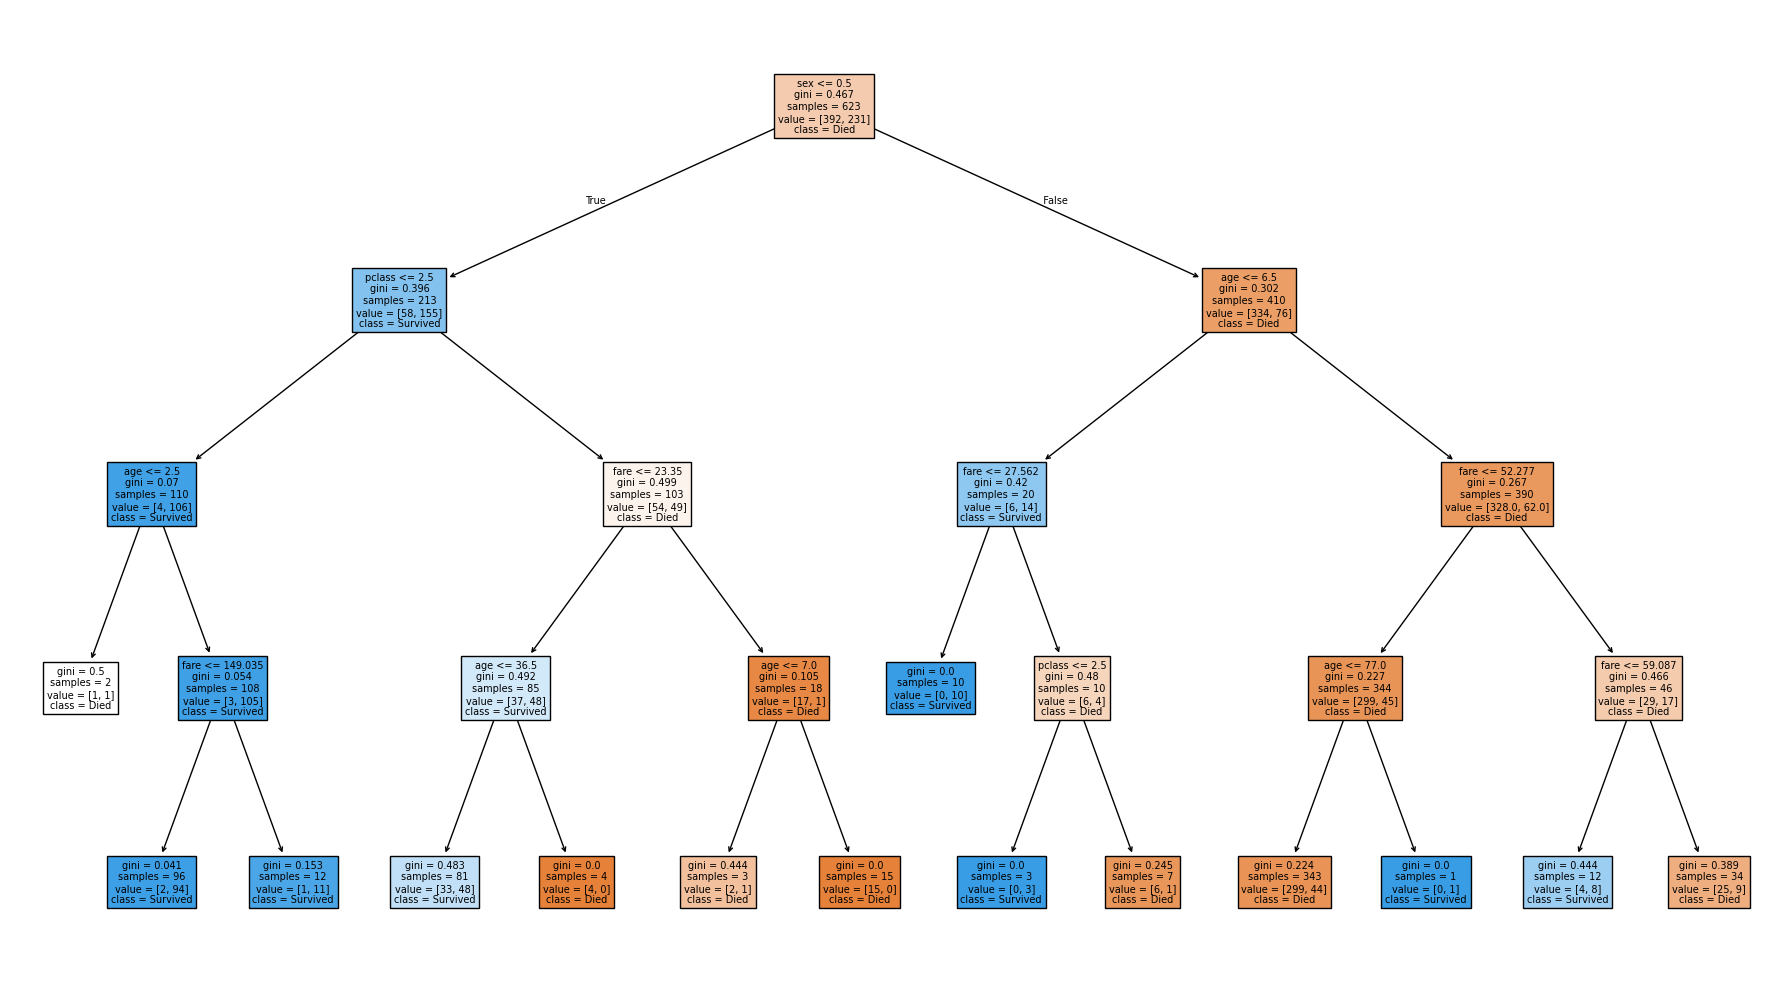

for sample split=15 , accuracy = 0.8171641791044776 
for sample split=20 , accuracy = 0.8171641791044776 
for sample split=25 , accuracy = 0.8208955223880597 
for sample split=30 , accuracy = 0.8208955223880597 


In [20]:
min_samples_splits = [5,10,15,20,25,30]
for split in min_samples_splits:
    model = DecisionTreeClassifier(max_depth = 4,min_samples_split = split )
    model.fit(X_train,y_train)

    acc = model.score(X_test,y_test)
    print(f"for sample split={split} , accuracy = {acc} ")

    if split== 10:
        plt.figure(figsize = (18,10))
        plot_tree(
            model,
            feature_names = X.columns,
            class_names = ["Died","Survived"],
            filled = True
        )

        plt.tight_layout()
        plt.show()

# post pruning

In [21]:
full_tree = DecisionTreeClassifier(random_state = 42)
full_tree.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [22]:
path = full_tree.cost_complexity_pruning_path(X_train,y_train)
ccp_alphas = path.ccp_alphas

print(ccp_alphas) # these are all the values on which bases we can simplify our tree further, meaning to generalise our tree

[0.         0.         0.00013376 0.00013376 0.00022931 0.00032103
 0.00048409 0.00053505 0.00053505 0.00053505 0.00062746 0.00064205
 0.00077709 0.00085607 0.00093633 0.00096308 0.00096308 0.00096308
 0.00099875 0.00101659 0.00104193 0.0010478  0.00107009 0.00109238
 0.00115927 0.0012352  0.00123729 0.00129646 0.00132211 0.00133563
 0.00137583 0.00137583 0.00139708 0.00143228 0.00144145 0.00150482
 0.00151596 0.00152184 0.00171215 0.00183444 0.0019012  0.00195674
 0.00200642 0.00214018 0.00233474 0.0024077  0.00260835 0.00263292
 0.00278606 0.00280169 0.00284379 0.00288925 0.00299625 0.00302412
 0.00431144 0.00495299 0.00577849 0.00589431 0.0074248  0.01236198
 0.01787674 0.04065074 0.1323581 ]


In [23]:
# train our model for all alphas
trees = []
for alpha in ccp_alphas:
    model = DecisionTreeClassifier(random_state = 42,ccp_alpha = alpha)
    model.fit(X_train,y_train)
    #acc = model.score(X_test,y_test)

    trees.append((model,alpha))
    

In [24]:
best_acc = 0
best_alpha= 0

for model, alpha in trees:
    curr_acc = acc = model.score(X_test,y_test)
    if curr_acc > best_acc:
        best_acc = curr_acc
        best_alpha = alpha
    

In [25]:
best_acc

0.8208955223880597

In [26]:
best_alpha

np.float64(0.0017121455323702516)

In [27]:
best_model = DecisionTreeClassifier(ccp_alpha = best_alpha)
best_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


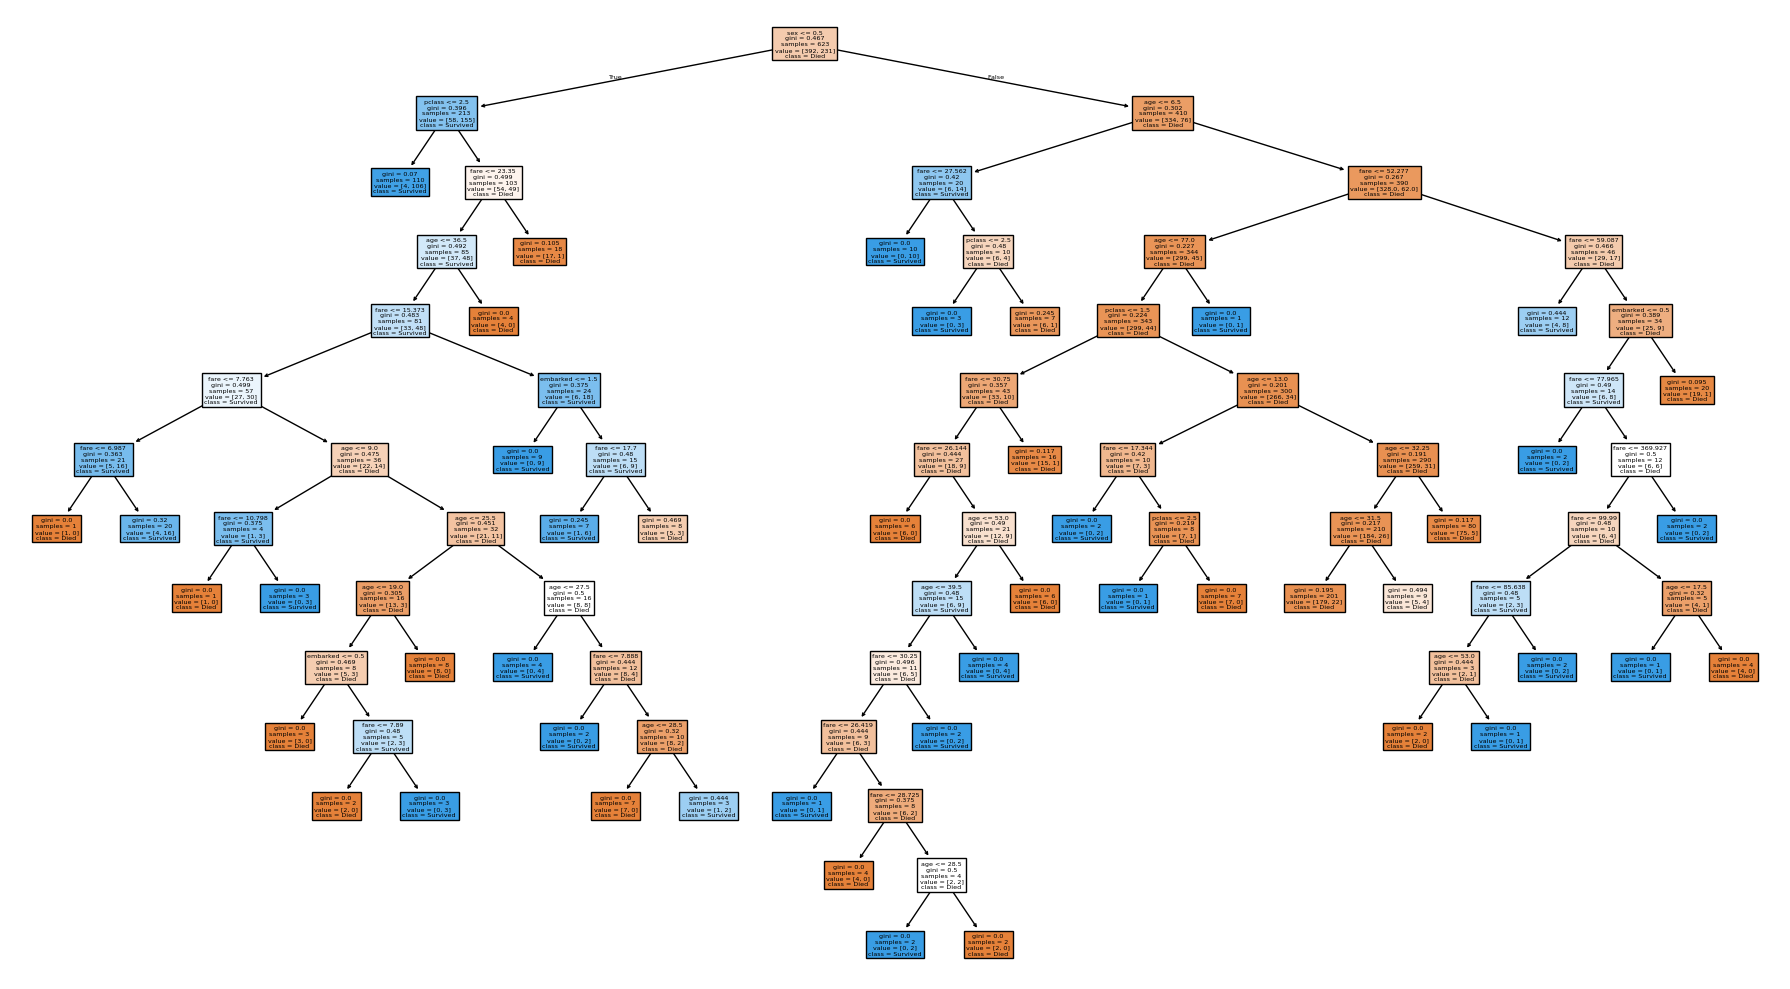

In [28]:
plt.figure(figsize = (18,10))
plot_tree(
    best_model,
    feature_names = X.columns,
    class_names = ["Died","Survived"],
    filled = True
)

plt.tight_layout()
plt.show()

In [29]:
print(best_model.score(X_test,y_test))  

0.8171641791044776


In [30]:
best_model = DecisionTreeClassifier(ccp_alpha = best_alpha, max_depth = 4)  # combination of both pruning by adding max_deptyh also  
best_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


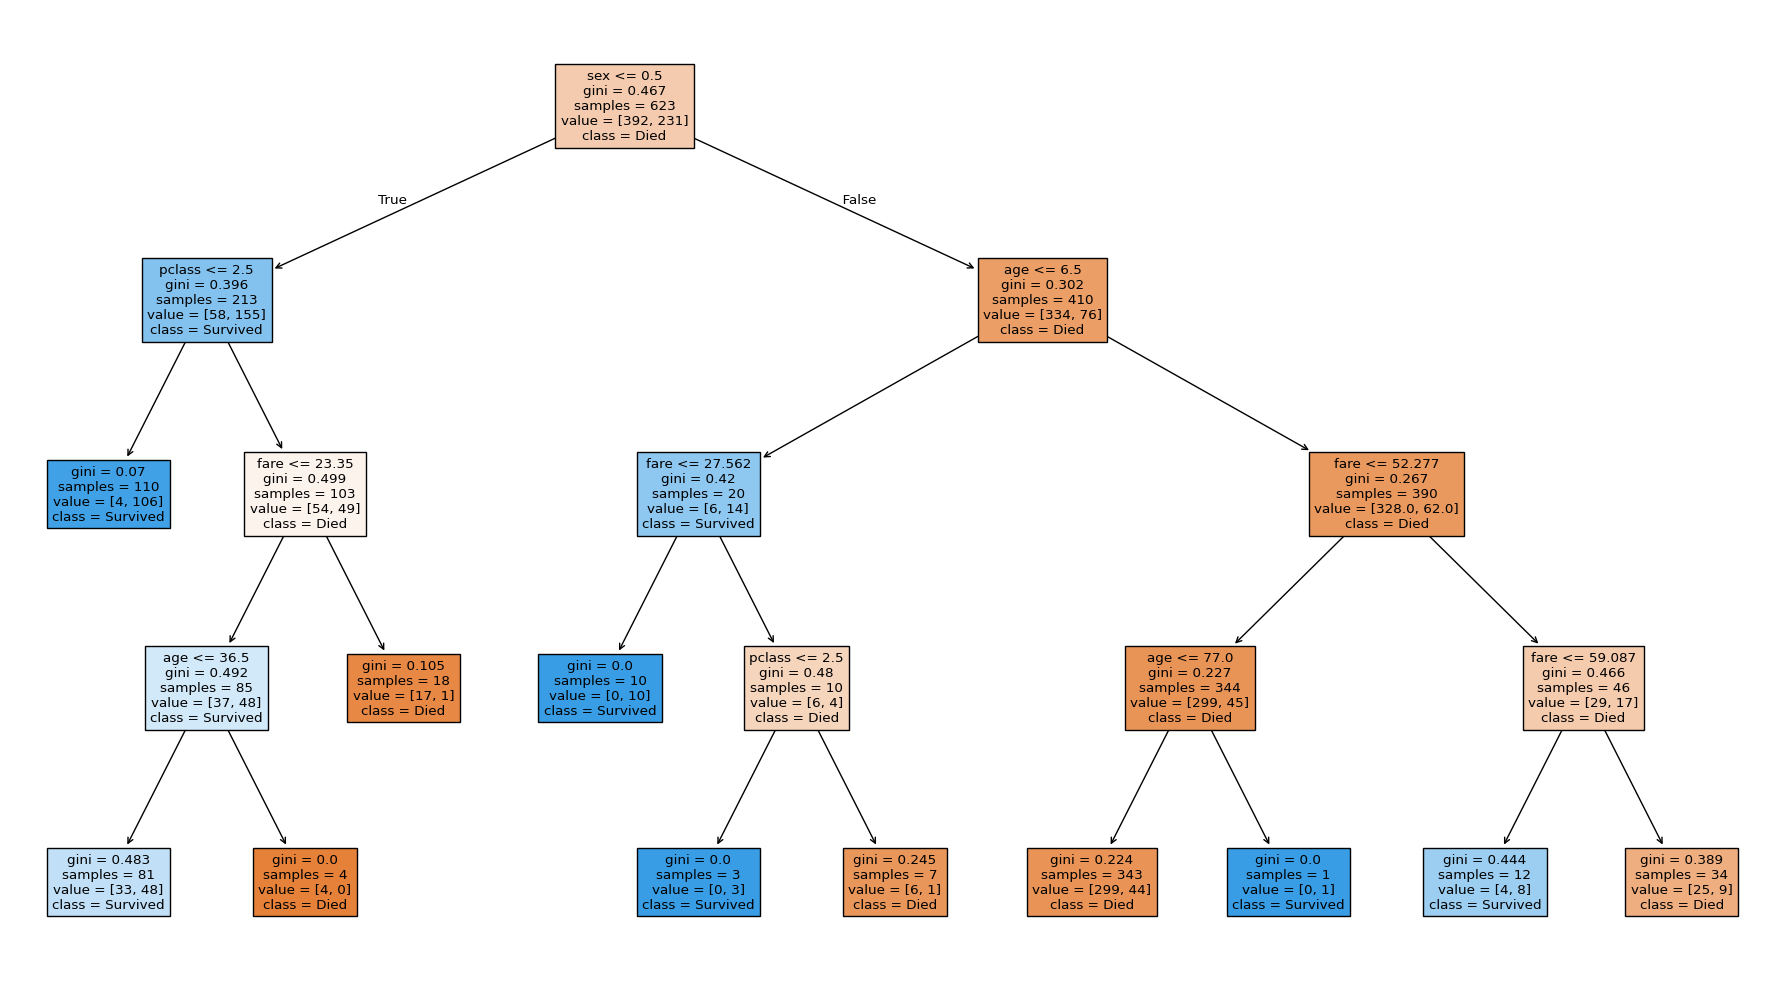

In [31]:
plt.figure(figsize = (18,10))
plot_tree(
    best_model,
    feature_names = X.columns,
    class_names = ["Died","Survived"],
    filled = True
)

plt.tight_layout()
plt.show()

In [32]:
print(best_model.score(X_test,y_test)) 

0.8246268656716418


In [39]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators =201,
    oob_score = True,
    max_depth = 4
)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
print("accuracy: ",rf.oob_score * 100 ,"%")
print("accuracy: ",accuracy_score(y_test,y_pred) * 100 ,"%")

accuracy:  100 %
accuracy:  81.34328358208955 %


In [38]:
titanic.shape

(891, 15)

In [40]:
from sklearn.ensemble import BaggingClassifier
base_model = DecisionTreeClassifier()

bagging = BaggingClassifier(
    base_model,
    n_estimators = 201,
)
bagging.fit(X_train,y_train)
y_pred = bagging.predict(X_test)
print("accuracy: ",accuracy_score(y_test,y_pred) * 100 ,"%")

accuracy:  77.23880597014924 %


In [41]:
from sklearn.linear_model import LogisticRegression
base_model =  LogisticRegression(max_iter = 1000)

bagging = BaggingClassifier(
    base_model,
    n_estimators = 201,
)
bagging.fit(X_train,y_train)
y_pred = bagging.predict(X_test)
print("accuracy: ",accuracy_score(y_test,y_pred) * 100 ,"%")

accuracy:  79.8507462686567 %
